In [4]:
%pip install matplotlib

/home/nguyenhuynh/Documents/appcuuho/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [9]:
DATA_PATH = "data_final_final.csv"
df = pd.read_csv(DATA_PATH)

# Danh sách cột user yêu cầu (theo đúng bạn đưa)
cols_user = [
    "contact",
    "disaster_type",
    "affected_people",
    "infracstructure_damage",   # user viết vậy, file có thể khác
    "is_isolated",
    "deathly",
    "has_emergency_terms",
    "has_emotional_terms",
    "has_emphasis",
    "label",
    "confident",
    "tinh_tp",
    "quan_huyen",
    "phuong_xa",
    "nha",
    "chỗ ở & nơi trú ẩn",
    "liên lạc & thông tin",
    "lương thực & nước uống",
    "phương tiện & cứu hộ",
    "thuốc men & hỗ trợ y tế",
    "vật dụng sinh hoạt",       # user viết vậy, file có thể khác
    "affected_people_log",
]

# Map các tên cột hay bị lệch/khác trong file
col_map = {
    "infracstructure_damage": "infrastructure_damage",
    "vật dụng sinh hoạt": "vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)"
}

# Lấy ra danh sách cột thực sự tồn tại trong file
selected_cols = []
missing_cols = []
for c in cols_user:
    real_c = col_map.get(c, c)
    if real_c in df.columns:
        selected_cols.append(real_c)
    else:
        missing_cols.append(c)

df_viz = df[selected_cols].copy()

print("Shape (rows, cols):", df_viz.shape)
print("\nMissing (không tìm thấy trong file):", missing_cols)
display(df_viz.head(3))
print("\nDtypes:")
print(df_viz.dtypes)


Shape (rows, cols): (483, 22)

Missing (không tìm thấy trong file): []


,contact,disaster_type,affected_people,infrastructure_damage,is_isolated,deathly,has_emergency_terms,has_emotional_terms,has_emphasis,label,...,quan_huyen,phuong_xa,nha,chỗ ở & nơi trú ẩn,liên lạc & thông tin,lương thực & nước uống,phương tiện & cứu hộ,thuốc men & hỗ trợ y tế,"vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)",affected_people_log
0,1,2,4.0,0,1,0,0,0,1,CAO,...,Huế,Kim Long,nhà số 9 kiệt 34 An Ninh,0,1,1,0,0,1,1.609438
1,0,2,0.0,1,1,1,1,1,0,CAO,...,Điện Bàn,Vĩnh Điện,NaN,0,1,1,0,1,0,0.000000
2,1,2,0.0,1,1,1,0,0,1,CAO,...,Đà Nẵng,Gò Nổi,thôn Tây An,1,1,1,1,1,0,0.000000



Dtypes:
contact                                                       int64
disaster_type                                                 int64
affected_people                                             float64
infrastructure_damage                                         int64
is_isolated                                                   int64
deathly                                                       int64
has_emergency_terms                                           int64
has_emotional_terms                                           int64
has_emphasis                                                  int64
label                                                        object
confident                                                    object
tinh_tp                                                      object
quan_huyen                                                   object
phuong_xa                                                    object
nha                                    

In [10]:
df_viz["label_clean"] = df_viz["label"].astype(str).str.strip().str.upper()
df_viz["confident_clean"] = df_viz["confident"].astype(str).str.strip().str.upper()

print("Label counts (clean):")
print(df_viz["label_clean"].value_counts())

print("\nConfident counts (clean):")
print(df_viz["confident_clean"].value_counts())


Label counts (clean):
label_clean
CAO           253
TRUNG BÌNH    159
THẤP           71
Name: count, dtype: int64

Confident counts (clean):
confident_clean
CAO     424
THẤP     59
Name: count, dtype: int64


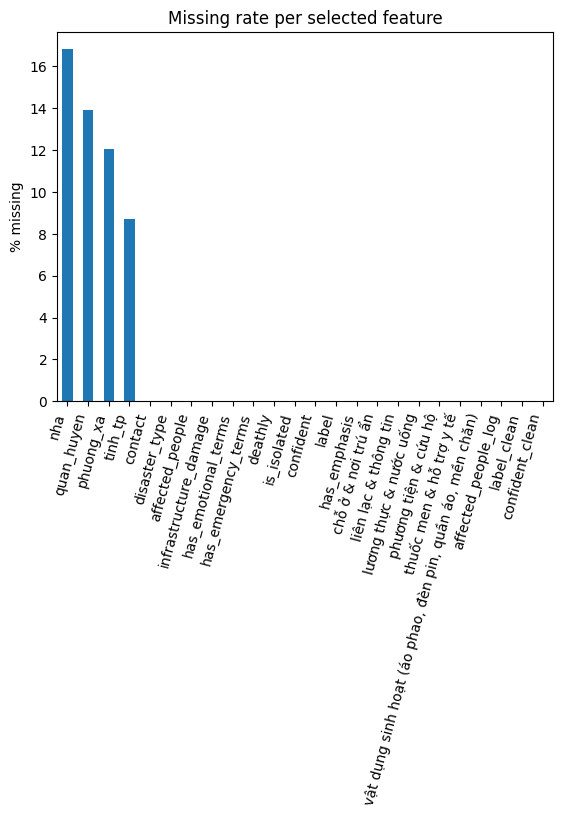

In [11]:
missing_rate = df_viz.isna().mean().sort_values(ascending=False) * 100

plt.figure()
missing_rate.plot(kind="bar")
plt.ylabel("% missing")
plt.title("Missing rate per selected feature")
plt.xticks(rotation=75, ha="right")
plt.show()


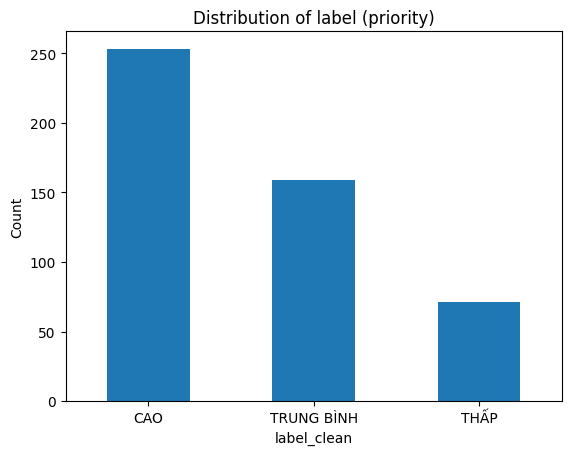

In [12]:
label_counts = df_viz["label_clean"].value_counts()

plt.figure()
label_counts.plot(kind="bar")
plt.ylabel("Count")
plt.title("Distribution of label (priority)")
plt.xticks(rotation=0)
plt.show()


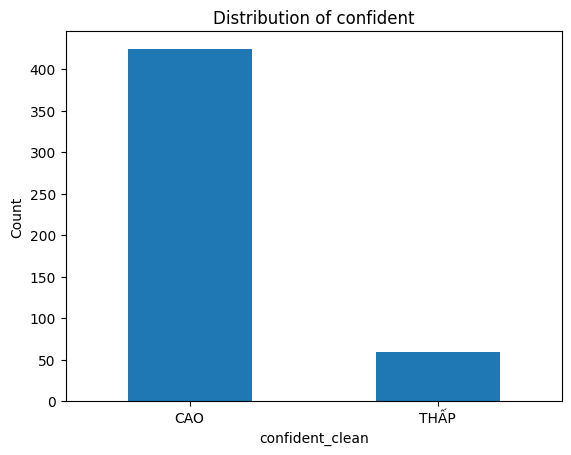

In [13]:
conf_counts = df_viz["confident_clean"].value_counts()

plt.figure()
conf_counts.plot(kind="bar")
plt.ylabel("Count")
plt.title("Distribution of confident")
plt.xticks(rotation=0)
plt.show()


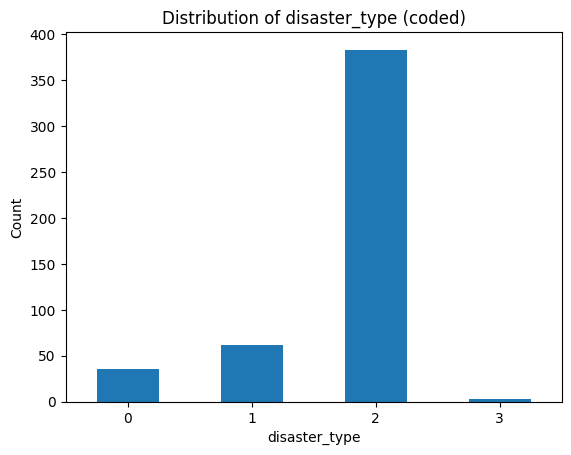

<Figure size 640x480 with 0 Axes>

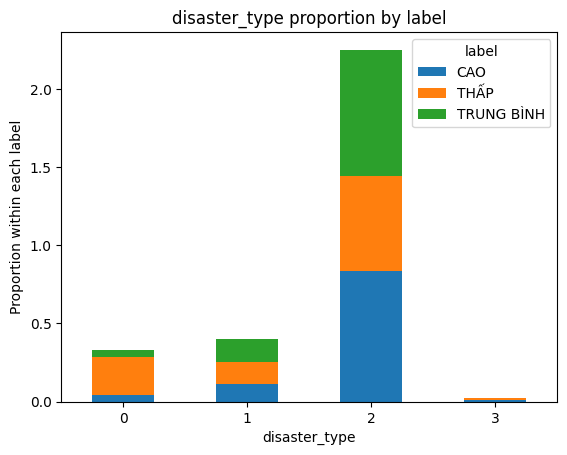

In [14]:
# 1) Distribution of disaster_type
dt_counts = df_viz["disaster_type"].value_counts().sort_index()

plt.figure()
dt_counts.plot(kind="bar")
plt.ylabel("Count")
plt.title("Distribution of disaster_type (coded)")
plt.xticks(rotation=0)
plt.show()

# 2) disaster_type vs label (normalized by label)
ct = pd.crosstab(df_viz["disaster_type"], df_viz["label_clean"], normalize="columns")

plt.figure()
ct.plot(kind="bar", stacked=True)
plt.ylabel("Proportion within each label")
plt.title("disaster_type proportion by label")
plt.legend(title="label")
plt.xticks(rotation=0)
plt.show()


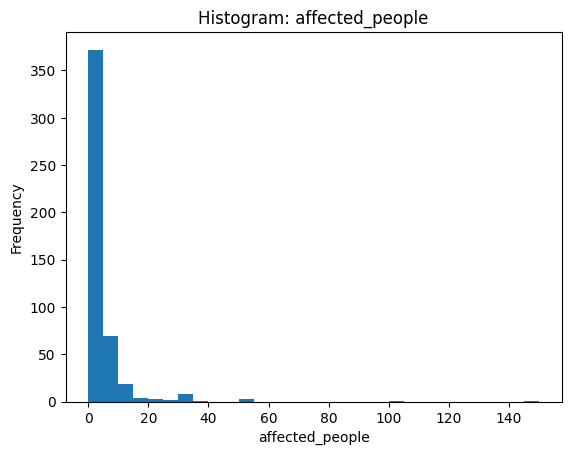

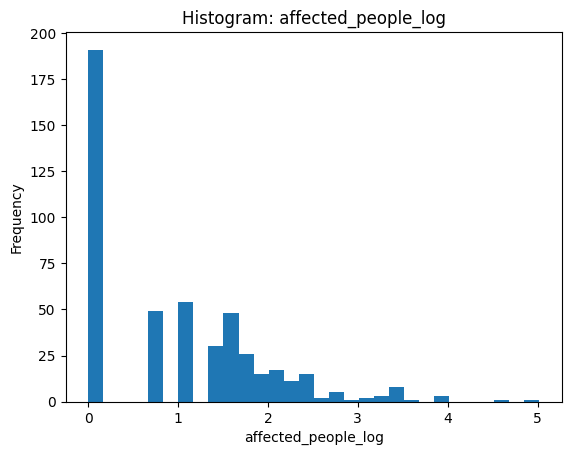

/tmp/ipykernel_3870690/33769424.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_box, labels=labels_order)


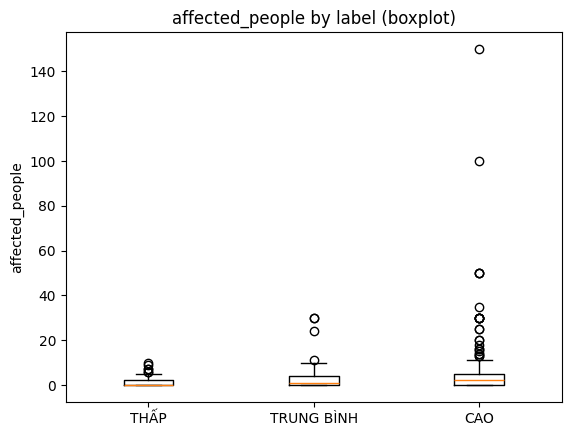

In [15]:
# Histogram affected_people
plt.figure()
df_viz["affected_people"].dropna().plot(kind="hist", bins=30)
plt.xlabel("affected_people")
plt.title("Histogram: affected_people")
plt.show()

# Histogram affected_people_log
plt.figure()
df_viz["affected_people_log"].dropna().plot(kind="hist", bins=30)
plt.xlabel("affected_people_log")
plt.title("Histogram: affected_people_log")
plt.show()

# Boxplot affected_people by label
labels_order = ["THẤP", "TRUNG BÌNH", "CAO"]
data_box = [df_viz.loc[df_viz["label_clean"] == lb, "affected_people"].dropna() for lb in labels_order]

plt.figure()
plt.boxplot(data_box, labels=labels_order)
plt.ylabel("affected_people")
plt.title("affected_people by label (boxplot)")
plt.show()


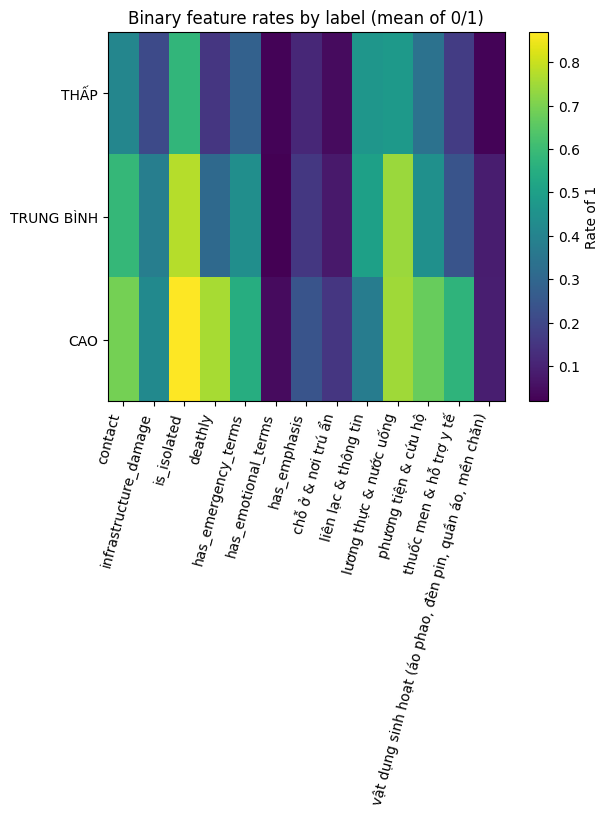

,contact,infrastructure_damage,is_isolated,deathly,has_emergency_terms,has_emotional_terms,has_emphasis,chỗ ở & nơi trú ẩn,liên lạc & thông tin,lương thực & nước uống,phương tiện & cứu hộ,thuốc men & hỗ trợ y tế,"vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)"
label_clean,,,,,,,,,,,,,
THẤP,0.408,0.211,0.577,0.155,0.282,0.028,0.113,0.042,0.465,0.479,0.338,0.169,0.028
TRUNG BÌNH,0.585,0.384,0.774,0.308,0.440,0.019,0.157,0.075,0.503,0.742,0.447,0.239,0.088
CAO,0.692,0.423,0.870,0.759,0.549,0.043,0.241,0.154,0.375,0.747,0.672,0.573,0.091


In [16]:
binary_cols = [
    "contact",
    "infrastructure_damage",
    "is_isolated",
    "deathly",
    "has_emergency_terms",
    "has_emotional_terms",
    "has_emphasis",
    "chỗ ở & nơi trú ẩn",
    "liên lạc & thông tin",
    "lương thực & nước uống",
    "phương tiện & cứu hộ",
    "thuốc men & hỗ trợ y tế",
    "vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)",
]

# Giữ lại những cột thật sự có trong df_viz
binary_cols = [c for c in binary_cols if c in df_viz.columns]

# Mean theo label => với biến 0/1, mean chính là tỷ lệ "1"
rate_by_label = df_viz.groupby("label_clean")[binary_cols].mean().reindex(["THẤP", "TRUNG BÌNH", "CAO"])

import matplotlib.pyplot as plt

plt.figure()
plt.imshow(rate_by_label.values, aspect="auto")
plt.yticks(range(rate_by_label.shape[0]), rate_by_label.index)
plt.xticks(range(rate_by_label.shape[1]), rate_by_label.columns, rotation=75, ha="right")
plt.colorbar(label="Rate of 1")
plt.title("Binary feature rates by label (mean of 0/1)")
plt.show()

display(rate_by_label.round(3))


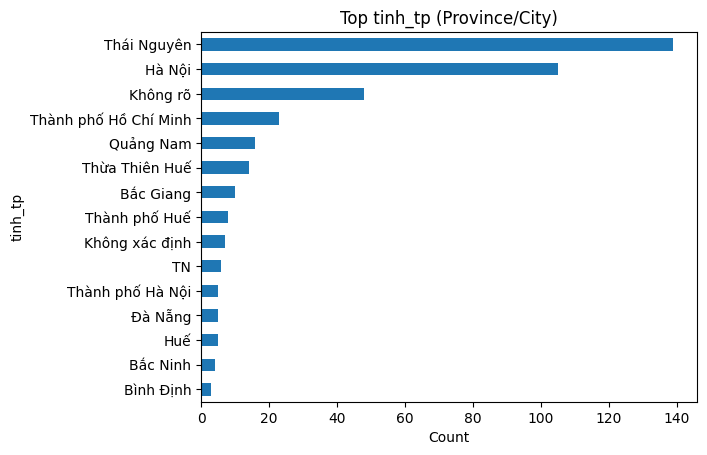

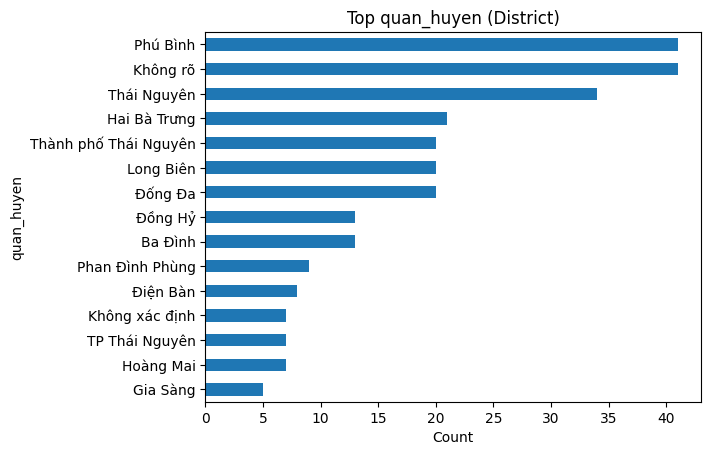

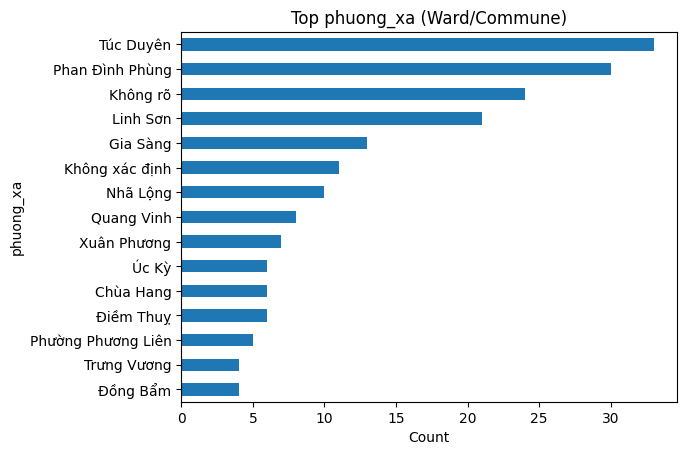

In [18]:
def plot_top_counts(series, title, top_n=15):
    vc = series.astype(str).str.strip().replace({"nan": np.nan}).dropna().value_counts().head(top_n)
    plt.figure()
    vc.sort_values().plot(kind="barh")
    plt.xlabel("Count")
    plt.title(title)
    plt.show()

plot_top_counts(df_viz["tinh_tp"], "Top tinh_tp (Province/City)", top_n=15)
plot_top_counts(df_viz["quan_huyen"], "Top quan_huyen (District)", top_n=15)
plot_top_counts(df_viz["phuong_xa"], "Top phuong_xa (Ward/Commune)", top_n=15)


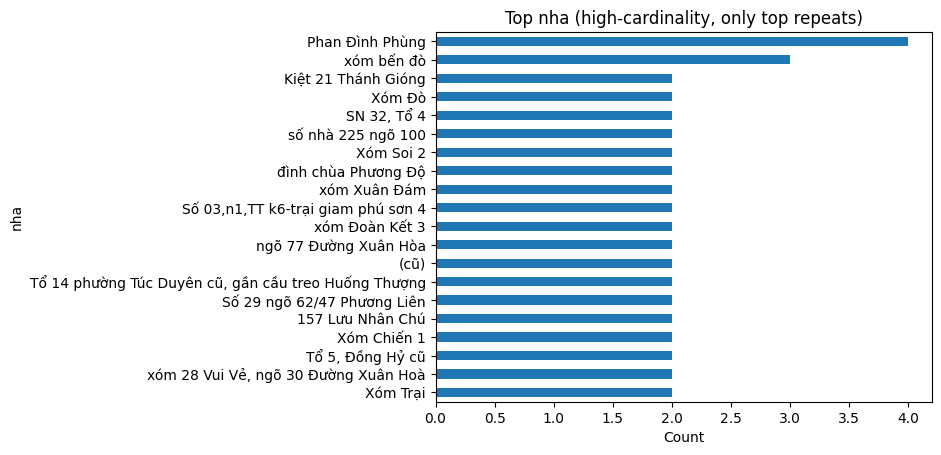

In [19]:
plot_top_counts(df_viz["nha"], "Top nha (high-cardinality, only top repeats)", top_n=20)


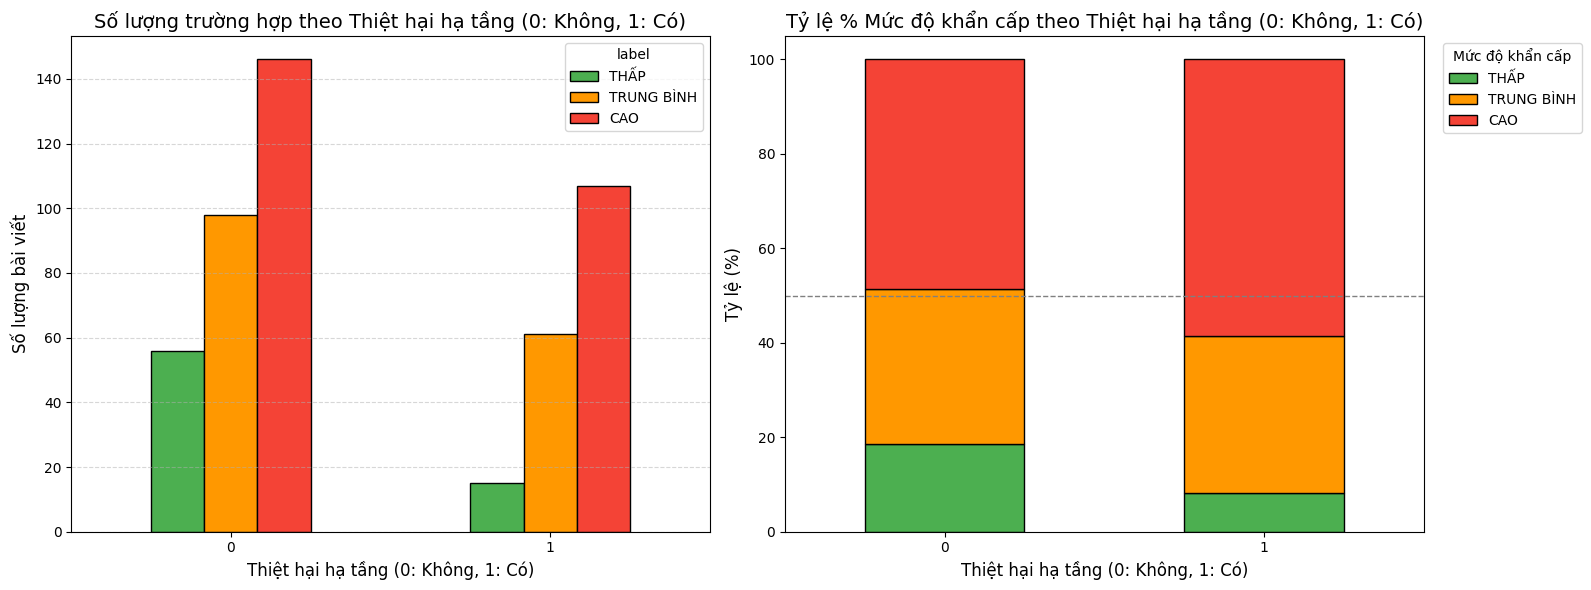

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dữ liệu
df = pd.read_csv('data_final_final.csv')

# 2. Làm sạch dữ liệu nhãn
# Chuyển về chữ hoa và xóa khoảng trắng thừa
df['label'] = df['label'].astype(str).str.upper().str.strip()

# Chỉ giữ lại các nhãn hợp lệ
valid_labels = ['THẤP', 'TRUNG BÌNH', 'CAO']
df_clean = df[df['label'].isin(valid_labels)].copy()

# Định nghĩa thứ tự hiển thị cho nhãn (để biểu đồ không bị lộn xộn)
label_order = ['THẤP', 'TRUNG BÌNH', 'CAO']
df_clean['label'] = pd.Categorical(df_clean['label'], categories=label_order, ordered=True)

# 3. Hàm vẽ biểu đồ phân tích quan hệ giữa Feature và Label
def plot_feature_vs_label(data, feature_col, target_col='label', feature_name_vn="Đặc trưng"):
    # Tạo bảng chéo (Crosstab)
    crosstab = pd.crosstab(data[feature_col], data[target_col])
    
    # Tính tỷ lệ % (Normalize theo hàng)
    crosstab_norm = crosstab.div(crosstab.sum(1), axis=0) * 100
    
    # Thiết lập khung hình
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    
    # Màu sắc cho các mức độ: Thấp (Xanh), TB (Cam), Cao (Đỏ)
    colors = ['#4CAF50', '#FF9800', '#F44336'] 
    
    # --- Biểu đồ 1: Số lượng tuyệt đối ---
    crosstab.plot(kind='bar', ax=ax[0], color=colors, edgecolor='black')
    ax[0].set_title(f'Số lượng trường hợp theo {feature_name_vn}', fontsize=14)
    ax[0].set_ylabel('Số lượng bài viết', fontsize=12)
    ax[0].set_xlabel(feature_name_vn, fontsize=12)
    ax[0].tick_params(axis='x', rotation=0)
    ax[0].grid(axis='y', linestyle='--', alpha=0.5)
    
    # --- Biểu đồ 2: Tỷ lệ phần trăm (Stacked) ---
    crosstab_norm.plot(kind='bar', stacked=True, ax=ax[1], color=colors, edgecolor='black')
    ax[1].set_title(f'Tỷ lệ % Mức độ khẩn cấp theo {feature_name_vn}', fontsize=14)
    ax[1].set_ylabel('Tỷ lệ (%)', fontsize=12)
    ax[1].set_xlabel(feature_name_vn, fontsize=12)
    ax[1].tick_params(axis='x', rotation=0)
    
    # Hiển thị chú thích (Legend) ra ngoài cho gọn
    ax[1].legend(title='Mức độ khẩn cấp', bbox_to_anchor=(1.02, 1), loc='upper left')
    
    # Thêm đường kẻ ngang 50% để dễ nhìn
    ax[1].axhline(y=50, color='gray', linestyle='--', linewidth=1)
    
    plt.tight_layout()
    plt.show()

# 4. Chạy hàm vẽ cho cột 'infrastructure_damage'
# Lưu ý: 0 = Không thiệt hại, 1 = Có thiệt hại
plot_feature_vs_label(
    df_clean, 
    feature_col='infrastructure_damage', 
    feature_name_vn='Thiệt hại hạ tầng (0: Không, 1: Có)'
)

# Bạn cũng có thể thử với các cột khác, ví dụ:
# plot_feature_vs_label(df_clean, feature_col='deathly', feature_name_vn='Có người tử vong')

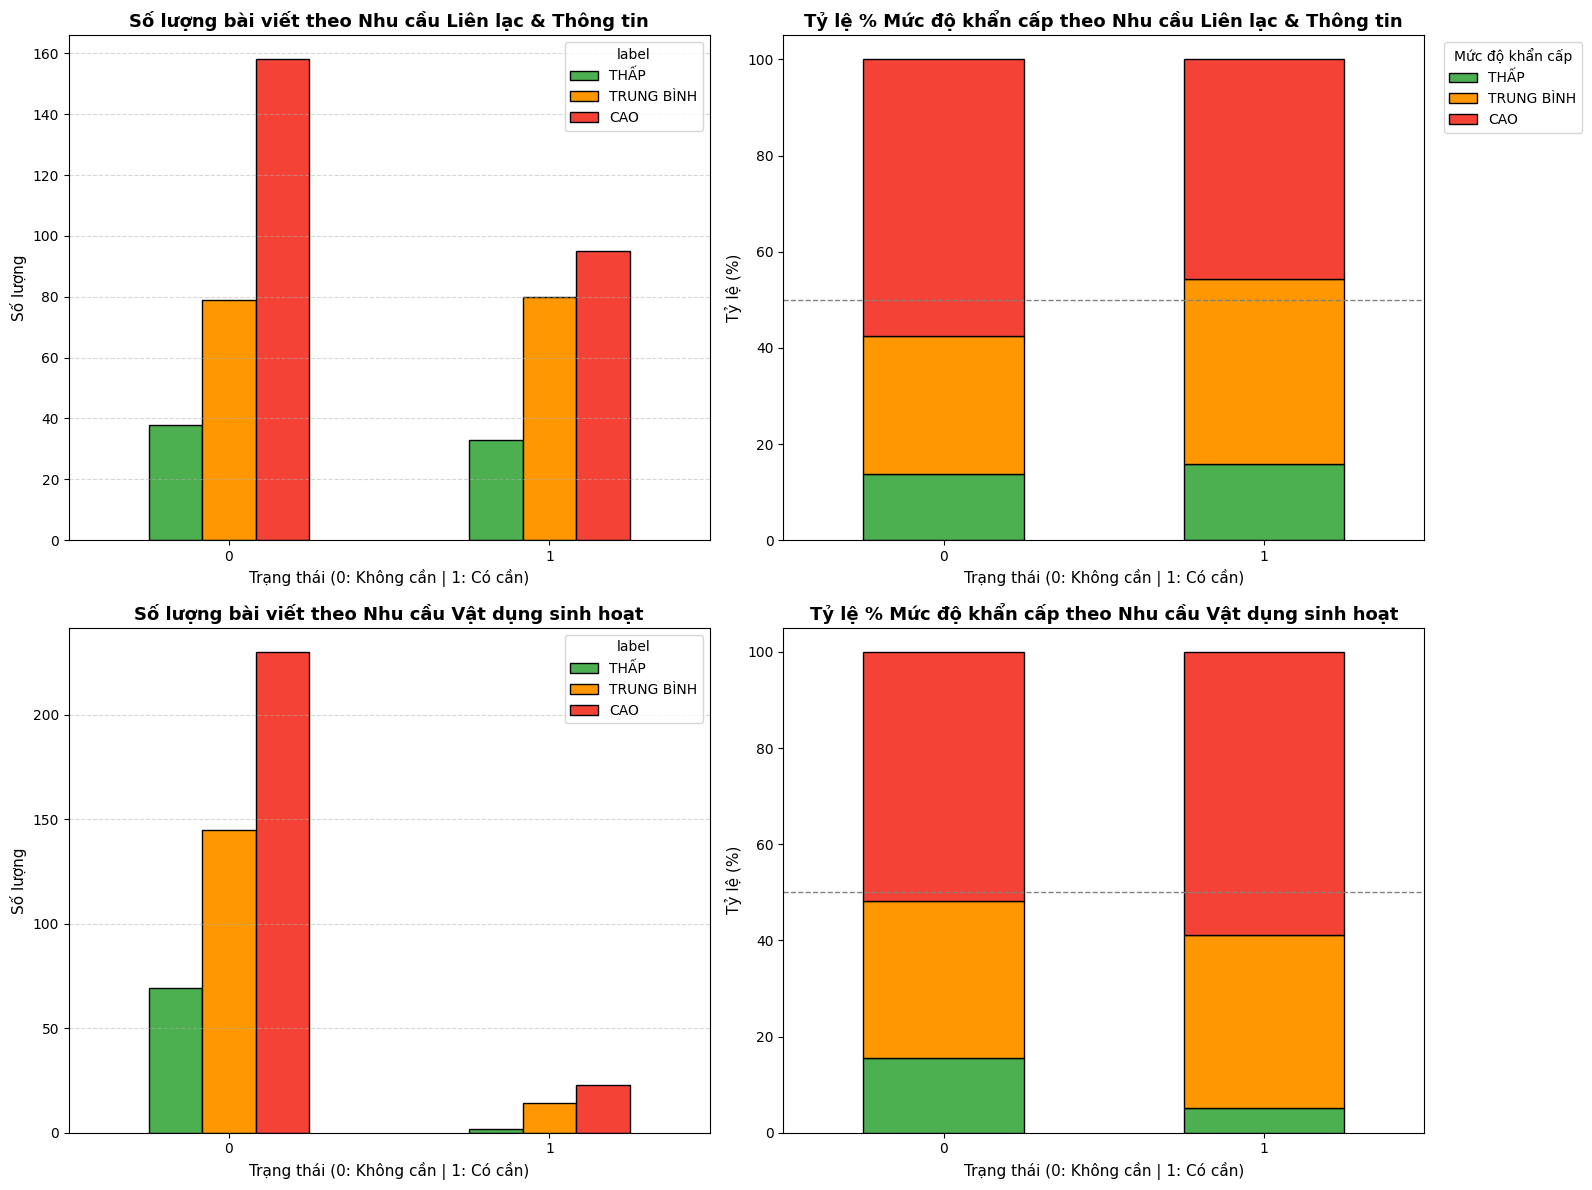

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dữ liệu
# Hãy đảm bảo file 'data_final_final.csv' nằm cùng thư mục với file code này
df = pd.read_csv('data_final_final.csv')

# 2. Làm sạch dữ liệu nhãn (Label)
# Chuyển về chữ hoa và xóa khoảng trắng thừa để tránh lỗi trùng lặp (ví dụ 'Cao' và 'CAO')
df['label'] = df['label'].astype(str).str.upper().str.strip()

# Chỉ giữ lại 3 nhãn chính thức và sắp xếp thứ tự logic
valid_labels = ['THẤP', 'TRUNG BÌNH', 'CAO']
df_clean = df[df['label'].isin(valid_labels)].copy()
df_clean['label'] = pd.Categorical(df_clean['label'], categories=valid_labels, ordered=True)

# 3. Định nghĩa danh sách các cột cần vẽ
# Dictionary: {Tên cột trong CSV : Tên hiển thị trên biểu đồ}
features_to_plot = {
    'liên lạc & thông tin': 'Nhu cầu Liên lạc & Thông tin',
    'vật dụng sinh hoạt (áo phao, đèn pin, quần áo, mền chăn)': 'Nhu cầu Vật dụng sinh hoạt'
}

# 4. Thiết lập khung hình vẽ (2 dòng, 2 cột)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
# Tăng khoảng cách giữa các biểu đồ để không bị dính chữ
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Màu sắc: Xanh (Thấp) -> Cam (TB) -> Đỏ (Cao)
colors = ['#4CAF50', '#FF9800', '#F44336']

# 5. Vòng lặp vẽ biểu đồ cho từng đặc trưng
for i, (col_name, display_name) in enumerate(features_to_plot.items()):
    # Tạo bảng thống kê chéo (Crosstab)
    # Bảng số lượng
    crosstab = pd.crosstab(df_clean[col_name], df_clean['label'])
    
    # Bảng tỷ lệ % (Chia cho tổng hàng rồi nhân 100)
    crosstab_norm = crosstab.div(crosstab.sum(1), axis=0) * 100
    
    # --- Vẽ Biểu đồ 1: Số lượng tuyệt đối (Cột bên trái) ---
    ax_count = axes[i, 0]
    crosstab.plot(kind='bar', ax=ax_count, color=colors, edgecolor='black', rot=0)
    
    ax_count.set_title(f'Số lượng bài viết theo {display_name}', fontsize=13, fontweight='bold')
    ax_count.set_ylabel('Số lượng', fontsize=11)
    ax_count.set_xlabel('Trạng thái (0: Không cần | 1: Có cần)', fontsize=11)
    ax_count.grid(axis='y', linestyle='--', alpha=0.5)
    
    # --- Vẽ Biểu đồ 2: Tỷ lệ phần trăm (Cột bên phải) ---
    ax_norm = axes[i, 1]
    crosstab_norm.plot(kind='bar', stacked=True, ax=ax_norm, color=colors, edgecolor='black', rot=0)
    
    ax_norm.set_title(f'Tỷ lệ % Mức độ khẩn cấp theo {display_name}', fontsize=13, fontweight='bold')
    ax_norm.set_ylabel('Tỷ lệ (%)', fontsize=11)
    ax_norm.set_xlabel('Trạng thái (0: Không cần | 1: Có cần)', fontsize=11)
    
    # Thêm đường kẻ ngang 50% để dễ so sánh
    ax_norm.axhline(y=50, color='gray', linestyle='--', linewidth=1)
    
    # Xử lý chú thích (Legend): Chỉ hiện ở biểu đồ đầu tiên cho gọn
    if i == 0:
        ax_norm.legend(title='Mức độ khẩn cấp', bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        ax_norm.get_legend().remove()

# 6. Lưu và hiển thị biểu đồ
plt.tight_layout()
plt.savefig('visualize_features.png') # Lưu ảnh
plt.show() # Hiển thị lên màn hình

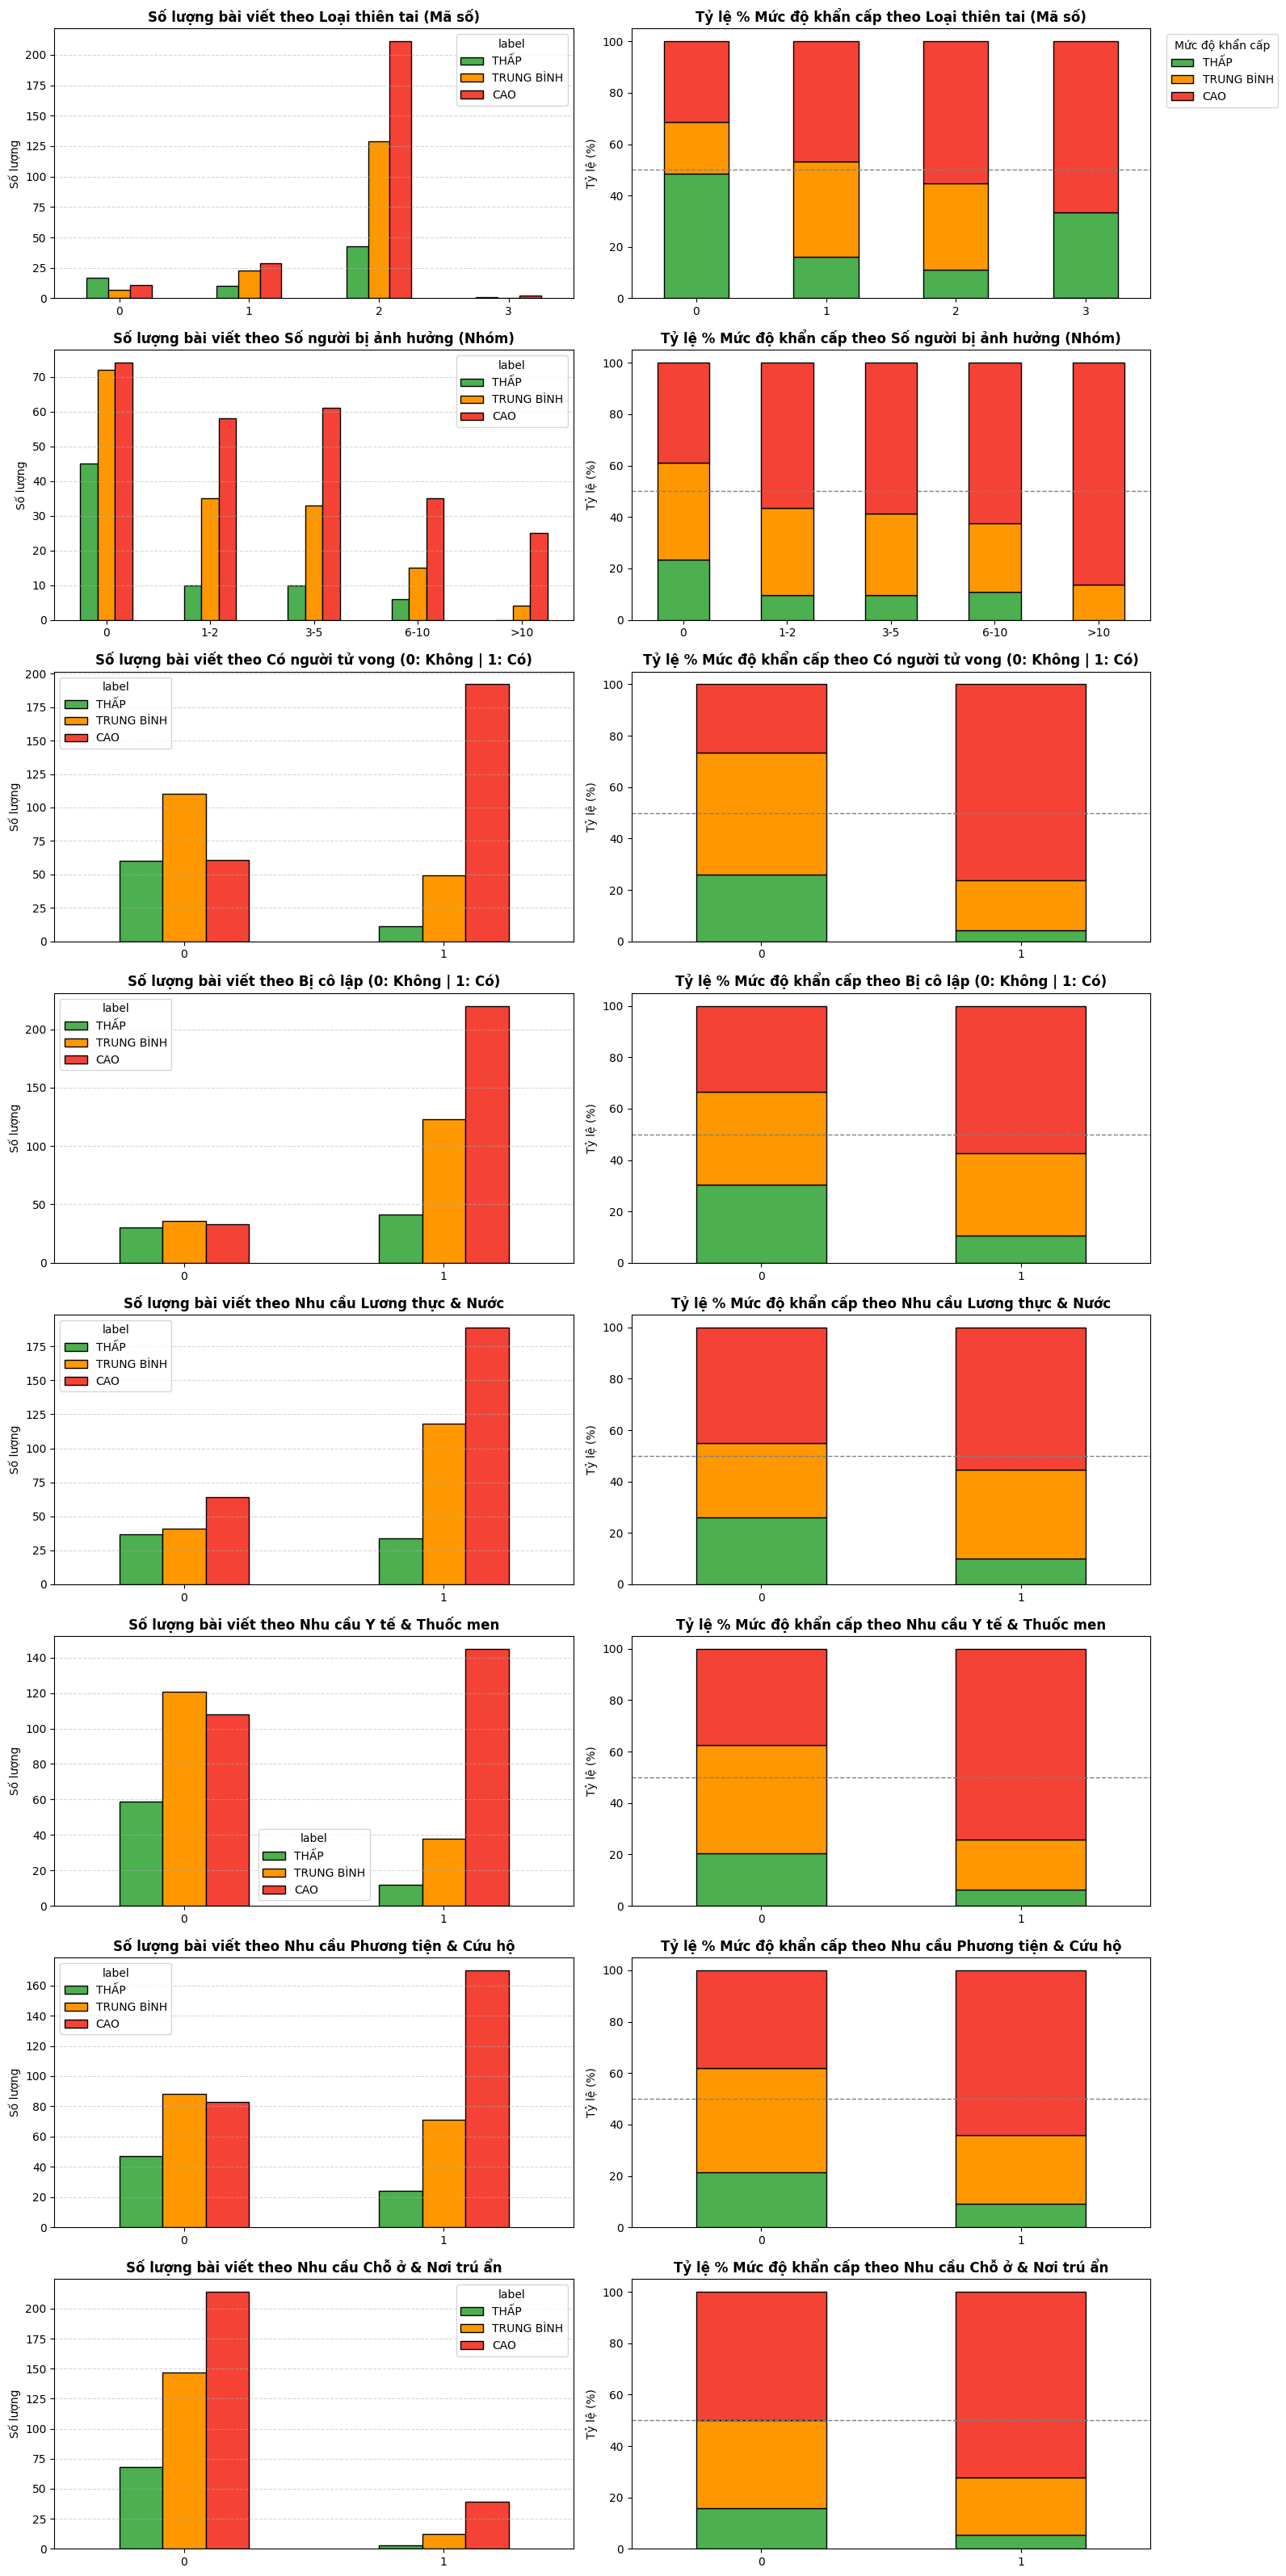

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load dữ liệu
# Đảm bảo file csv nằm cùng thư mục
df = pd.read_csv('data_final_final.csv')

# 2. Làm sạch dữ liệu nhãn (Target Label)
# Chuyển về chữ hoa, xóa khoảng trắng
df['label'] = df['label'].astype(str).str.upper().str.strip()

# Chỉ lấy 3 nhãn hợp lệ và sắp xếp thứ tự logic
valid_labels = ['THẤP', 'TRUNG BÌNH', 'CAO']
df_clean = df[df['label'].isin(valid_labels)].copy()
df_clean['label'] = pd.Categorical(df_clean['label'], categories=valid_labels, ordered=True)

# 3. Xử lý cột 'affected_people' (Binning)
# Chia thành các nhóm để dễ quan sát xu hướng
bins = [-1, 0, 2, 5, 10, 1000]
labels_people = ['0', '1-2', '3-5', '6-10', '>10']
df_clean['affected_people_group'] = pd.cut(df_clean['affected_people'], bins=bins, labels=labels_people)

# 4. Danh sách các đặc trưng cần vẽ
# Format: (Tên cột trong data, Tên hiển thị trên biểu đồ)
features_map = [
    ('disaster_type', 'Loại thiên tai (Mã số)'),
    ('affected_people_group', 'Số người bị ảnh hưởng (Nhóm)'),
    ('deathly', 'Có người tử vong (0: Không | 1: Có)'),
    ('is_isolated', 'Bị cô lập (0: Không | 1: Có)'),
    ('lương thực & nước uống', 'Nhu cầu Lương thực & Nước'),
    ('thuốc men & hỗ trợ y tế', 'Nhu cầu Y tế & Thuốc men'),
    ('phương tiện & cứu hộ', 'Nhu cầu Phương tiện & Cứu hộ'),
    ('chỗ ở & nơi trú ẩn', 'Nhu cầu Chỗ ở & Nơi trú ẩn')
]

# 5. Thiết lập khung hình lớn (8 dòng x 2 cột)
fig, axes = plt.subplots(nrows=8, ncols=2, figsize=(16, 32))
# Tăng khoảng cách để không bị dính chữ
plt.subplots_adjust(hspace=0.6, wspace=0.3)

# Màu sắc: Xanh (Thấp) -> Cam (TB) -> Đỏ (Cao)
colors = ['#4CAF50', '#FF9800', '#F44336'] 

# 6. Vòng lặp vẽ từng đặc trưng
for i, (col, title) in enumerate(features_map):
    # Tạo bảng thống kê
    crosstab = pd.crosstab(df_clean[col], df_clean['label'])
    # Tính tỷ lệ %
    crosstab_norm = crosstab.div(crosstab.sum(1), axis=0) * 100
    
    # --- Biểu đồ 1: Số lượng tuyệt đối (Cột trái) ---
    ax_abs = axes[i, 0]
    crosstab.plot(kind='bar', ax=ax_abs, color=colors, edgecolor='black', rot=0)
    ax_abs.set_title(f'Số lượng bài viết theo {title}', fontweight='bold', fontsize=12)
    ax_abs.set_ylabel('Số lượng')
    ax_abs.set_xlabel('')
    ax_abs.grid(axis='y', linestyle='--', alpha=0.5)
    
    # --- Biểu đồ 2: Tỷ lệ phần trăm (Cột phải) ---
    ax_pct = axes[i, 1]
    crosstab_norm.plot(kind='bar', stacked=True, ax=ax_pct, color=colors, edgecolor='black', rot=0)
    ax_pct.set_title(f'Tỷ lệ % Mức độ khẩn cấp theo {title}', fontweight='bold', fontsize=12)
    ax_pct.set_ylabel('Tỷ lệ (%)')
    ax_pct.set_xlabel('')
    ax_pct.axhline(y=50, color='gray', linestyle='--', linewidth=1) # Đường mốc 50%
    
    # Xử lý chú thích (Legend) chỉ hiện ở dòng đầu tiên
    if i == 0:
        ax_pct.legend(title='Mức độ khẩn cấp', bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        ax_pct.get_legend().remove()

# 7. Lưu ảnh và hiển thị
plt.tight_layout()
plt.savefig('visualize_all_features.png')
plt.show()

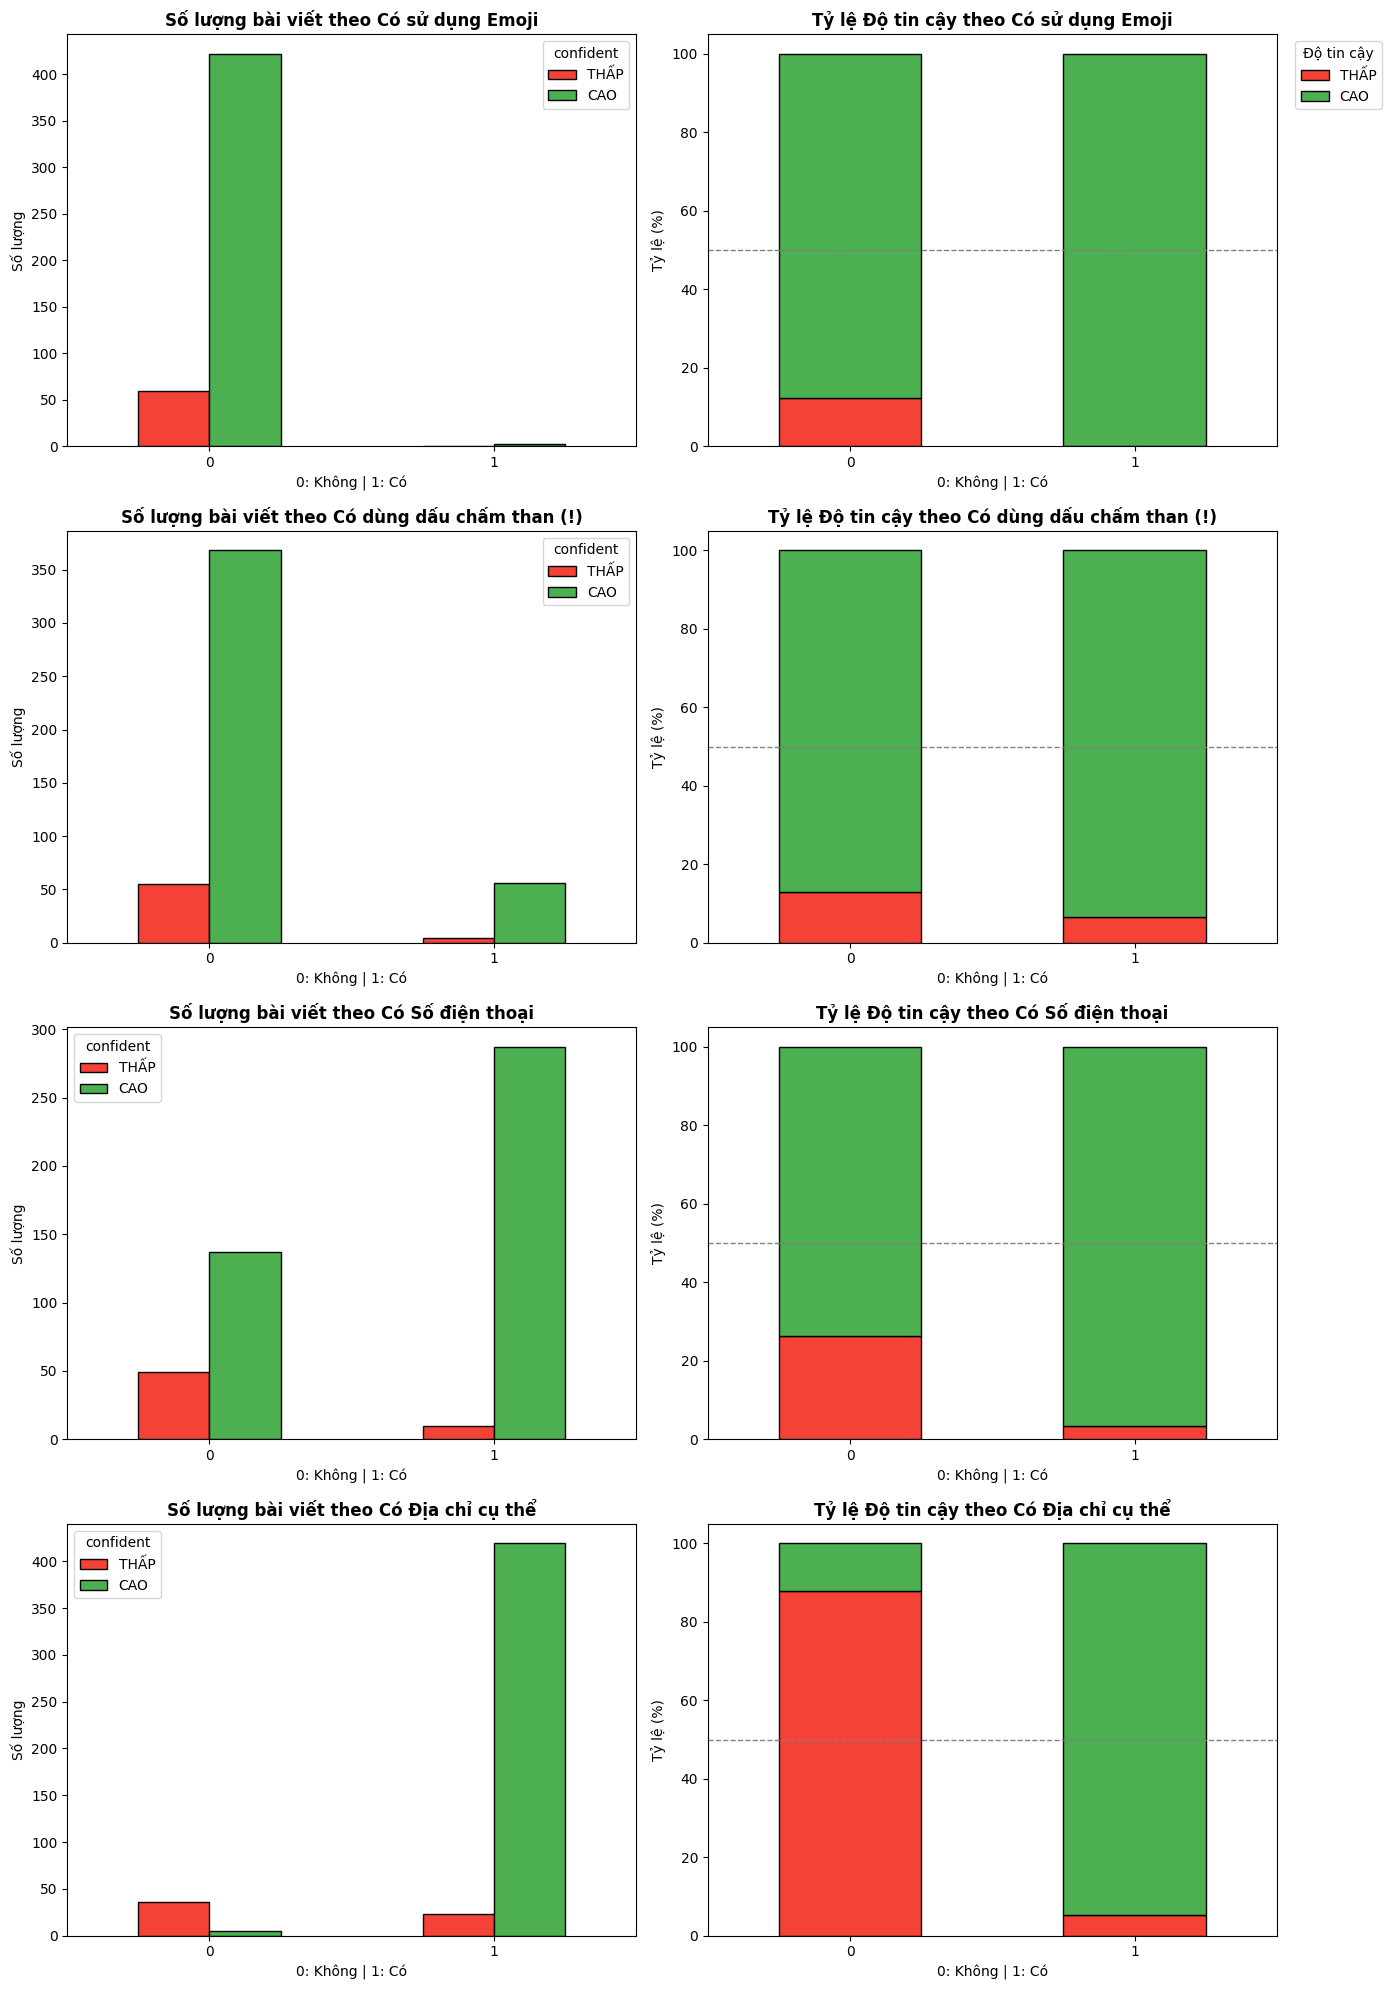

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# 1. Load dữ liệu
df = pd.read_csv('data_final_final.csv')

# 2. Chuẩn bị dữ liệu
# Làm sạch cột confident
df['confident'] = df['confident'].astype(str).str.upper().str.strip()
# Chỉ giữ lại 2 nhãn chính để so sánh rõ ràng
valid_confs = ['THẤP', 'CAO']
df_clean = df[df['confident'].isin(valid_confs)].copy()
df_clean['confident'] = pd.Categorical(df_clean['confident'], categories=valid_confs, ordered=True)

# 3. Tạo các đặc trưng mới (Feature Engineering)
# a) Có Emoji (Sử dụng regex dải unicode cơ bản cho emoji)
emoji_pattern = re.compile(r'[\U00010000-\U0010ffff]', flags=re.UNICODE)
df_clean['has_emoji'] = df_clean['content'].apply(lambda x: 1 if emoji_pattern.search(str(x)) else 0)

# b) Có dấu chấm than (!)
df_clean['has_exclamation'] = df_clean['content'].str.contains('!').astype(int)

# c) Có SĐT (đã có sẵn cột contact)
df_clean['has_phone'] = df_clean['contact']

# d) Có Địa chỉ (Kiểm tra cột location không rỗng)
df_clean['has_address'] = df_clean['location'].apply(lambda x: 1 if pd.notna(x) and str(x).strip() != '' else 0)

# 4. Vẽ biểu đồ
features_list = [
    ('has_emoji', 'Có sử dụng Emoji'),
    ('has_exclamation', 'Có dùng dấu chấm than (!)'),
    ('has_phone', 'Có Số điện thoại'),
    ('has_address', 'Có Địa chỉ cụ thể')
]

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 20))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Màu: Đỏ (Thấp) - Xanh (Cao)
colors = ['#F44336', '#4CAF50']

for i, (col, title) in enumerate(features_list):
    # Tạo bảng thống kê
    ct = pd.crosstab(df_clean[col], df_clean['confident'])
    ct_norm = ct.div(ct.sum(1), axis=0) * 100
    
    # Biểu đồ 1: Số lượng tuyệt đối
    ct.plot(kind='bar', ax=axes[i, 0], color=colors, edgecolor='black', rot=0)
    axes[i, 0].set_title(f'Số lượng bài viết theo {title}', fontsize=12, fontweight='bold')
    axes[i, 0].set_ylabel('Số lượng')
    axes[i, 0].set_xlabel('0: Không | 1: Có')
    
    # Biểu đồ 2: Tỷ lệ %
    ct_norm.plot(kind='bar', stacked=True, ax=axes[i, 1], color=colors, edgecolor='black', rot=0)
    axes[i, 1].set_title(f'Tỷ lệ Độ tin cậy theo {title}', fontsize=12, fontweight='bold')
    axes[i, 1].set_ylabel('Tỷ lệ (%)')
    axes[i, 1].set_xlabel('0: Không | 1: Có')
    axes[i, 1].axhline(y=50, color='gray', linestyle='--', linewidth=1)
    
    if i == 0:
        axes[i, 1].legend(title='Độ tin cậy', bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        axes[i, 1].get_legend().remove()

plt.tight_layout()
plt.savefig('confidence_analysis.png')
plt.show()